In [1]:
from google.colab import files

uploaded = files.upload()

Saving netflix_titles.csv to netflix_titles.csv


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("netflix_titles.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:

# STEP 4: DATA CLEANING

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Remove unnecessary spaces from text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Convert date_added to datetime
df["date_added"] = pd.to_datetime(
    df["date_added"].str.strip(),
    format="mixed",
    errors="coerce"
)

# Fill missing text values for analysis
text_columns = [
    "director", "cast", "country", "rating",
    "duration", "listed_in", "description"
]

for col in text_columns:
    df[col] = df[col].fillna("Unknown")

# Check the cleaned dataset
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned dataset shape:", df.shape)

df.head()


Missing values before cleaning:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Duplicate rows: 0

Missing values after cleaning:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

Cleaned dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [5]:

df.to_csv("netflix_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


type
Movie      6131
TV Show    2676
Name: count, dtype: int64


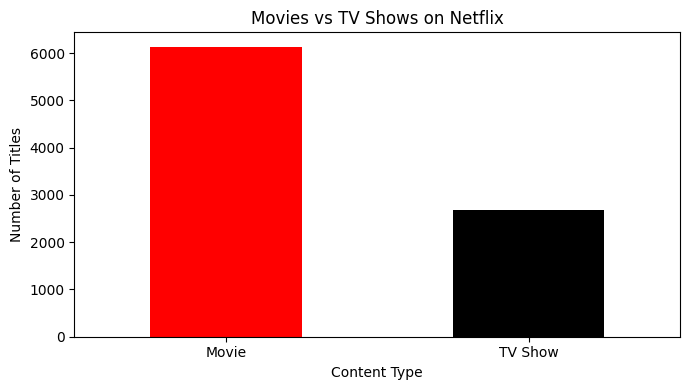

In [6]:

content_counts = df["type"].value_counts()

print(content_counts)

content_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Movies vs TV Shows on Netflix",
    color=["red", "black"]
)

plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


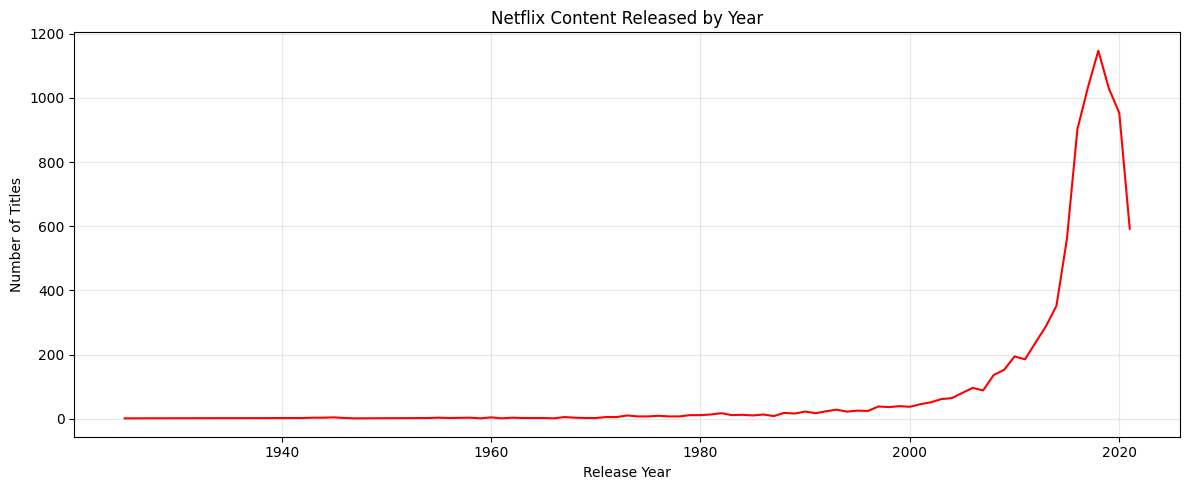

In [7]:

# Content released by year

yearly_content = df["release_year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
yearly_content.plot(kind="line", color="red")

plt.title("Netflix Content Released by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


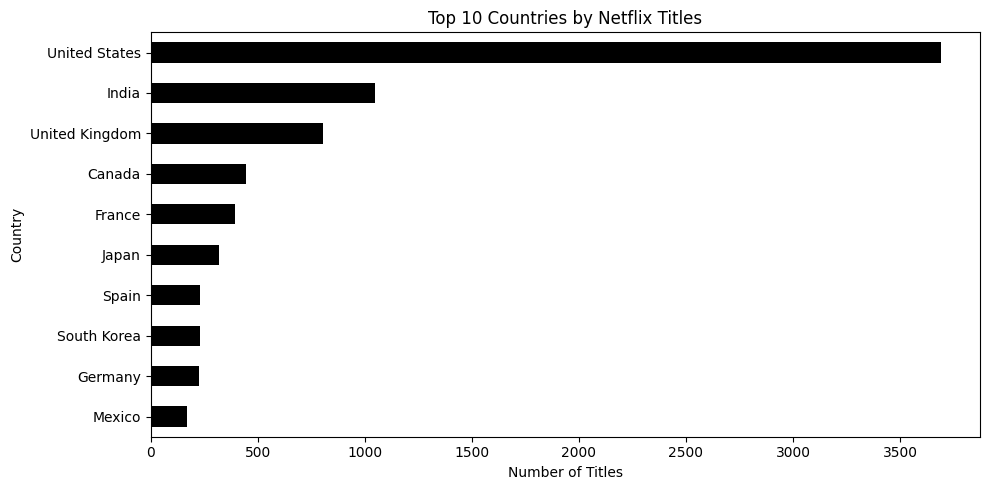

In [8]:

# Top 10 countries by number of titles

country_data = df[df["country"] != "Unknown"].copy()

country_data["country"] = country_data["country"].str.split(", ")
country_data = country_data.explode("country")

top_countries = country_data["country"].value_counts().head(10)

plt.figure(figsize=(10, 5))
top_countries.sort_values().plot(kind="barh", color="black")

plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


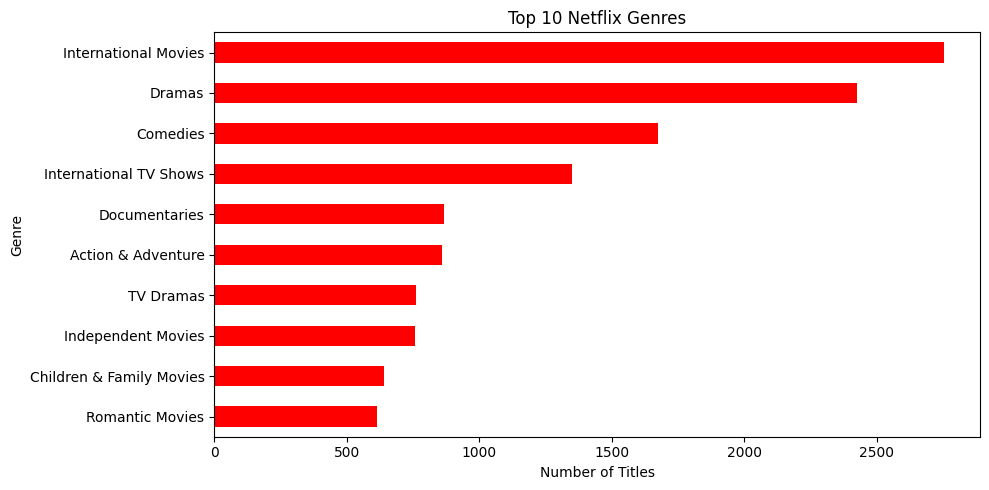

In [9]:

# Top 10 genres on Netflix

genre_data = df[df["listed_in"] != "Unknown"].copy()

genre_data["listed_in"] = genre_data["listed_in"].str.split(", ")
genre_data = genre_data.explode("listed_in")

top_genres = genre_data["listed_in"].value_counts().head(10)

plt.figure(figsize=(10, 5))
top_genres.sort_values().plot(kind="barh", color="red")

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


In [10]:

import os

os.makedirs("project_outputs", exist_ok=True)

df.to_csv("project_outputs/netflix_cleaned.csv", index=False)

print("Cleaned dataset saved!")
print("You can now save each chart using plt.savefig() before plt.show() in its chart cell.")


Cleaned dataset saved!
You can now save each chart using plt.savefig() before plt.show() in its chart cell.


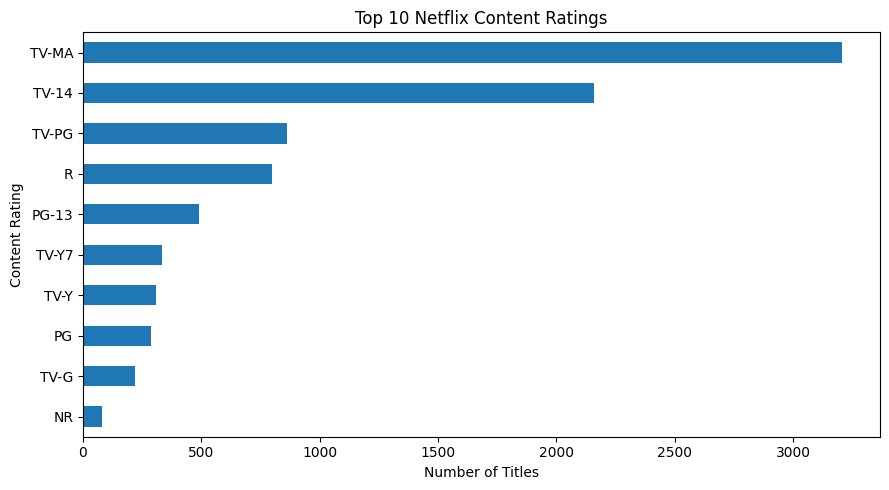

In [11]:

# Top 10 Netflix content ratings

rating_counts = (
    df.loc[df["rating"] != "Unknown", "rating"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(9, 5))
rating_counts.sort_values().plot(kind="barh")

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")
plt.tight_layout()
plt.savefig("ratings_analysis.png", dpi=300, bbox_inches="tight")
plt.show()


         Count  Percentage
type                      
Movie     6131       69.62
TV Show   2676       30.38


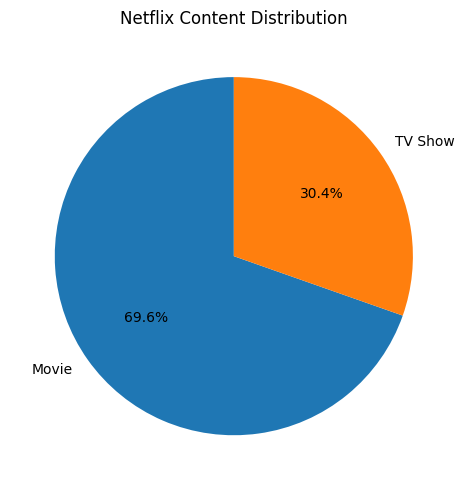

In [12]:

# Movies vs TV Shows: count and percentage

type_summary = df["type"].value_counts().to_frame(name="Count")
type_summary["Percentage"] = (
    type_summary["Count"] / len(df) * 100
).round(2)

print(type_summary)

plt.figure(figsize=(7, 5))
plt.pie(
    type_summary["Count"],
    labels=type_summary.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Netflix Content Distribution")
plt.tight_layout()
plt.savefig("content_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


In [13]:

# BUSINESS INSIGHTS

print("=" * 45)
print("NETFLIX DATA ANALYTICS - KEY FINDINGS")
print("=" * 45)

print(f"\n1. Total titles analyzed: {len(df)}")

print("\n2. Content type distribution:")
print(df["type"].value_counts().to_string())

print("\n3. Top 5 release years:")
print(df["release_year"].value_counts().head(5).to_string())

print("\n4. Top 5 content ratings:")
print(
    df.loc[df["rating"] != "Unknown", "rating"]
    .value_counts()
    .head(5)
    .to_string()
)

print("\n5. Top 5 genres:")
print(top_genres.head(5).to_string())

print("\n6. Top 5 countries:")
print(top_countries.head(5).to_string())

print("\nAnalysis completed successfully!")


NETFLIX DATA ANALYTICS - KEY FINDINGS

1. Total titles analyzed: 8807

2. Content type distribution:
type
Movie      6131
TV Show    2676

3. Top 5 release years:
release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902

4. Top 5 content ratings:
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490

5. Top 5 genres:
listed_in
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1351
Documentaries              869

6. Top 5 countries:
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393

Analysis completed successfully!


In [15]:

import os
import shutil

os.makedirs("netflix_project/charts", exist_ok=True)
os.makedirs("netflix_project/data", exist_ok=True)

# Save cleaned data
df.to_csv(
    "netflix_project/data/netflix_cleaned.csv",
    index=False
)

# Save the charts generated earlier
figures = [
    ("ratings_analysis.png", "ratings_analysis.png"),
    ("content_distribution.png", "content_distribution.png")
]

for source, destination in figures:
    if os.path.exists(source):
        shutil.copy(
            source,
            f"netflix_project/charts/{destination}"
        )

print("Project data and available charts saved!")


Project data and available charts saved!


In [16]:

readme = """
# Netflix Data Analytics Project

## Project Overview
An exploratory data analysis project examining Netflix
movies and TV shows using Python.

## Objectives
- Analyze movies and TV show distribution.
- Explore release-year trends.
- Identify common genres and countries.
- Examine content ratings.
- Generate insights from the dataset.

## Tools Used
- Python
- Pandas
- Matplotlib
- Seaborn
- Google Colab

## Workflow
1. Load the dataset.
2. Inspect and clean missing values and duplicates.
3. Perform exploratory data analysis.
4. Create visualizations.
5. Summarize findings and limitations.

## Project Structure
- data/: Cleaned dataset
- charts/: Analysis visualizations
- Netflix_Data_Analysis.ipynb: Notebook

## Dataset
Netflix Movies and TV Shows dataset:
https://www.kaggle.com/datasets/shivamb/netflix-shows

## Findings
See the notebook for data-driven findings and charts.

## Limitations
The analysis describes the available dataset.
It does not establish why content was added or
prove audience popularity or viewing performance.

## Author
Sanhofer Saghanaas
"""

with open("netflix_project/README.md", "w", encoding="utf-8") as f:
    f.write(readme.strip())

print("README created successfully!")


README created successfully!
